Dataset Shape: 1300 rows, 31 columns



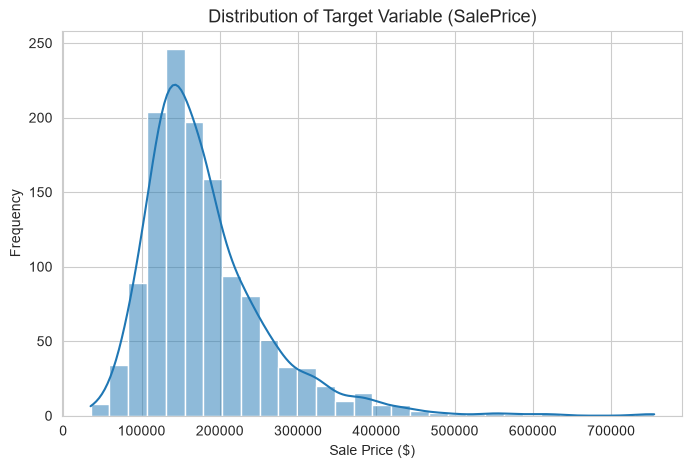

SalePrice Skewness: 1.96

Target Summary Statistics:
count      1300.000000
mean     180983.514615
std       80096.642018
min       34900.000000
25%      130000.000000
50%      163000.000000
75%      213310.000000
max      755000.000000
Name: SalePrice, dtype: float64
=== Features with Missing Values (%) ===
Alley          94.076923
LotFrontage    17.615385
GarageType      5.538462
dtype: float64
=== Top 10 Positive Correlations with SalePrice ===
OverallQual     0.787937
GrLivArea       0.710247
GarageCars      0.641674
GarageArea      0.620809
TotalBsmtSF     0.603631
1stFlrSF        0.597568
FullBath        0.559997
TotRmsAbvGrd    0.540520
YearBuilt       0.521406
YearRemodAdd    0.512167
Name: SalePrice, dtype: float64


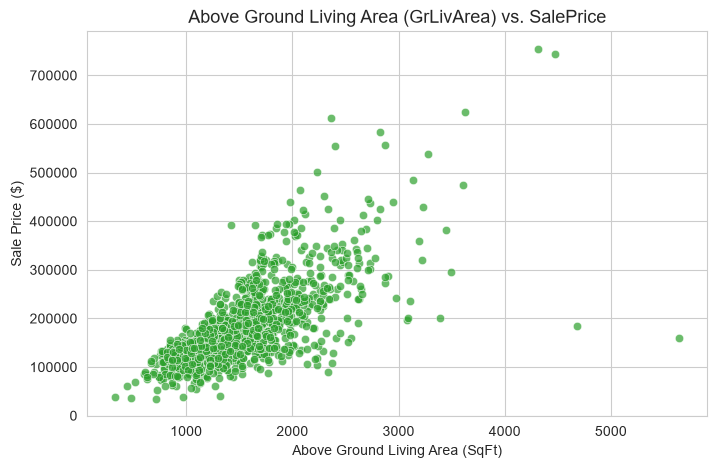

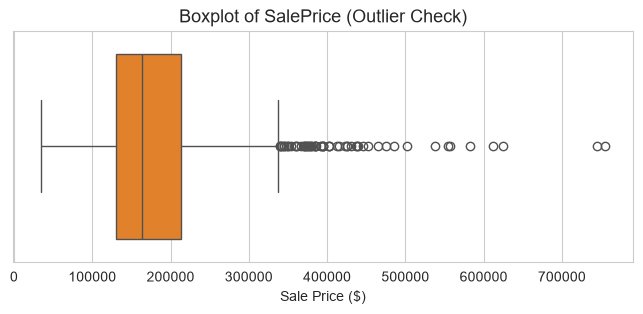

Training partition shape: (1040, 29) | Testing partition shape: (260, 29)
=== 5-Fold Cross-Validation Performance ===
            Model  CV RMSE Mean ($)  CV RMSE Std ($)
Linear Regression          35704.07          9040.39
 Ridge Regression          35220.78          9308.55
=== Final Test Set Metrics ===
                       Model  RMSE ($)   MAE ($)  R² Score
Linear Regression (Baseline) 34714.699 20156.865     0.771
    Ridge Regression (α=1.0) 34366.206 19860.362     0.776


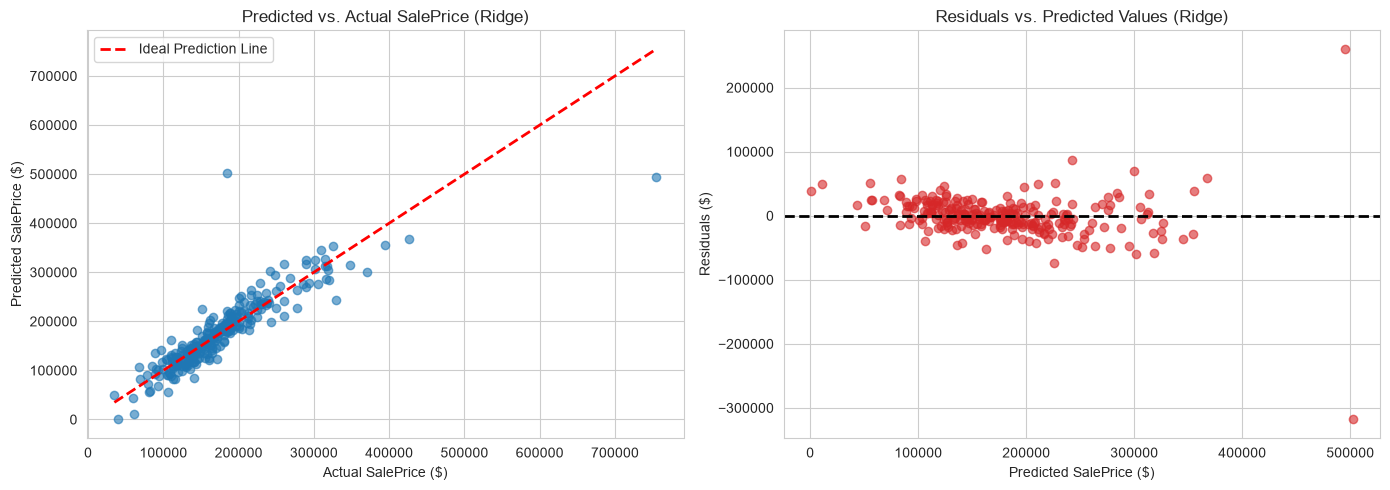

C:\Users\Admin\AppData\Local\Temp\ipykernel_24976\1932711602.py:251: UserWarning: The design matrix is poorly conditioned (condition number=1.56e+17). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_train_df.values, i)
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.

=== Top 10 High Multicollinearity Features (VIF > 10 Indicates High Correlation) ===
             Feature          VIF
Neighborhood_Blueste 129106725.42
      RoofStyle_Shed  31224683.17
     BldgType_Duplex   5311856.88
 Neighborhood_Timber   4224783.18
Neighborhood_Blmngtn   3906764.96
   HouseStyle_2Story   3896858.68
   GarageType_2Types   3892855.85
      RoofStyle_Flat   3211322.74
   HouseStyle_1.5Unf   2737472.34
Neighborhood_NoRidge   2520469.18


c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\Admin\OneDrive\Documents\Projects\Portfolio_Projects\house-price-prediction\ven

In [11]:
# %% [markdown]
# # House Sale Price Prediction & Exploratory Analysis
# **Author:** Portfolio Project  
# **Objective:** Analyze key residential property valuation drivers, perform exploratory data analysis (EDA), address multicollinearity, and evaluate baseline Linear Regression against hyperparameter-tuned Ridge Regression.

# %% [markdown]
# ## 1. Setup & Environment Configuration

# %%
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Global display and visualization settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# Load Dataset
df = pd.read_excel("../data/HousePricesDataset.xlsx")

# Initial shape and preview
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()
# %% [markdown]
# ## 2. Exploratory Data Analysis (EDA)

# %%
# Target Variable Distribution
y = df["SalePrice"]
X = df.drop("SalePrice", axis=1)

plt.figure(figsize=(8, 5))
sns.histplot(y, bins=30, kde=True, color="#1f77b4")
plt.title("Distribution of Target Variable (SalePrice)", fontsize=13)
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.show()

print(f"SalePrice Skewness: {y.skew():.2f}")
print("\nTarget Summary Statistics:")
print(y.describe())

# %%
# Inspect Missing Values
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

print("=== Features with Missing Values (%) ===")
print(missing_pct)

# %%
# Top Numeric Correlations with SalePrice
numeric_df = df.select_dtypes(include=[np.number])
correlations = (
    numeric_df.corr()["SalePrice"].sort_values(ascending=False).drop("SalePrice")
)

print("=== Top 10 Positive Correlations with SalePrice ===")
print(correlations.head(10))

# %%
# Key Bivariate Relationship: Living Area vs. SalePrice
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"], alpha=0.7, color="#2ca02c")
plt.title("Above Ground Living Area (GrLivArea) vs. SalePrice", fontsize=13)
plt.xlabel("Above Ground Living Area (SqFt)")
plt.ylabel("Sale Price ($)")
plt.show()

# %%
# Target Outlier Inspection
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["SalePrice"], color="#ff7f0e")
plt.title("Boxplot of SalePrice (Outlier Check)", fontsize=13)
plt.xlabel("Sale Price ($)")
plt.show()

# %% [markdown]
# ## 3. Data Preprocessing & Pipeline Construction

# %%
# Drop non-predictive Identifier column
if "Id" in X.columns:
    X = X.drop("Id", axis=1)

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

print(
    f"Training partition shape: {X_train.shape} | Testing partition shape: {X_test.shape}"
)

# Identify numerical vs categorical column sets
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(exclude=["int64", "float64"]).columns

# Transformer Pipelines
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ]
)

# %% [markdown]
# ## 4. Model Training & Cross-Validation

# %%
# Model 1: Baseline Linear Regression
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])

# Model 2: Regularized Ridge Regression
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0)),
])

# Fit models on training data
linear_pipeline.fit(X_train, y_train)
ridge_pipeline.fit(X_train, y_train)

# 5-Fold Cross-Validation Evaluation (Training Stability)
lin_cv_scores = -cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=5,
)
ridge_cv_scores = -cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=5,
)

cv_results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "CV RMSE Mean ($)": [lin_cv_scores.mean(), ridge_cv_scores.mean()],
    "CV RMSE Std ($)": [lin_cv_scores.std(), ridge_cv_scores.std()],
})
print("=== 5-Fold Cross-Validation Performance ===")
print(cv_results.round(2).to_string(index=False))

# %% [markdown]
# ## 5. Held-Out Test Performance Evaluation

# %%
def evaluate_pipeline(model, X_test, y_test):
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return rmse, mae, r2, y_pred


lin_rmse, lin_mae, lin_r2, y_pred_lin = evaluate_pipeline(
    linear_pipeline, X_test, y_test
)
ridge_rmse, ridge_mae, ridge_r2, y_pred_ridge = evaluate_pipeline(
    ridge_pipeline, X_test, y_test
)

test_results = pd.DataFrame({
    "Model": ["Linear Regression (Baseline)", "Ridge Regression (α=1.0)"],
    "RMSE ($)": [lin_rmse, ridge_rmse],
    "MAE ($)": [lin_mae, ridge_mae],
    "R² Score": [lin_r2, ridge_r2],
})

print("=== Final Test Set Metrics ===")
print(test_results.round(3).to_string(index=False))

# %% [markdown]
# ## 6. Model Diagnostics & Residual Analysis

# %%
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted Plot
axes[0].scatter(y_test, y_pred_ridge, alpha=0.6, color="#1f77b4")
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
    label="Ideal Prediction Line",
)
axes[0].set_title("Predicted vs. Actual SalePrice (Ridge)", fontsize=12)
axes[0].set_xlabel("Actual SalePrice ($)")
axes[0].set_ylabel("Predicted SalePrice ($)")
axes[0].legend()

# Residual Plot
residuals = y_test - y_pred_ridge
axes[1].scatter(y_pred_ridge, residuals, alpha=0.6, color="#d62728")
axes[1].axhline(0, color="black", linestyle="--", lw=2)
axes[1].set_title("Residuals vs. Predicted Values (Ridge)", fontsize=12)
axes[1].set_xlabel("Predicted SalePrice ($)")
axes[1].set_ylabel("Residuals ($)")

plt.tight_layout()
plt.show()

# %% [markdown]
# ## 7. Multicollinearity Assessment (VIF Analysis)

# %%
# Transform training set to inspect feature inflation
X_train_proc = preprocessor.fit_transform(X_train)
if hasattr(X_train_proc, "toarray"):
    X_train_proc = X_train_proc.toarray()

# Retrieve encoded feature names
cat_onehot_names = (
    preprocessor.named_transformers_["cat"]
    .named_steps["onehot"]
    .get_feature_names_out(cat_cols)
)
all_feature_names = np.concatenate([num_cols, cat_onehot_names])

X_train_df = pd.DataFrame(X_train_proc, columns=all_feature_names)

# Compute Variance Inflation Factors
vif_list = [
    variance_inflation_factor(X_train_df.values, i)
    for i in range(X_train_df.shape[1])
]
vif_df = pd.DataFrame({"Feature": X_train_df.columns, "VIF": vif_list})

# Clean infinite values and sort top collinear drivers
vif_clean = (
    vif_df.replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values("VIF", ascending=False)
)

print("=== Top 10 High Multicollinearity Features (VIF > 10 Indicates High Correlation) ===")
print(vif_clean.head(10).round(2).to_string(index=False))